# Credit Risk Classifier: Predicting Loan Repayment

**Author:** Boualem Pereira · [GitHub](https://github.com/BoualemP)

## Overview

A lender wants to know, at origination time, which borrowers are likely to **pay off** their loan and which are likely to end up **in collection**.

| Model | Role |
|---|---|
| Logistic Regression | Primary, interpretable scoring model |
| Decision Tree | Rule-based, explainable model |
| Support Vector Machine | Non-linear challenger |
| Weekend rule | Business-rule benchmark |
| Majority class | Naive benchmark |

**Approach**

1. Exploratory analysis of the borrower profile against the loan outcome.
2. Feature engineering: weekend origination flag, gender, education.
3. Hyper-parameter tuning with stratified 5-fold cross-validation.
4. Evaluation on an independent hold-out set, focused on the loans that end in collection.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score,
                             f1_score, jaccard_score, log_loss, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", palette="Set1")
pd.set_option("display.precision", 3)

RANDOM_STATE = 42
DATA_DIR = Path("data")
TARGET = "loan_status"
POSITIVE_LABEL = "PAIDOFF"
# Raw label -> clean feature name ("Bechalor" is misspelled in the source data).
# "Master or Above" is the reference level and is left out of the one-hot encoding.
EDUCATION_LEVELS = {"High School or Below": "high_school_or_below", "college": "college", "Bechalor": "bachelor"}
NEGATIVE_LABEL = "COLLECTION"

## 2. Data

Each record describes a past loan: principal, payment terms, origination and due dates, and the borrower's age, education and gender. The target `loan_status` is either `PAIDOFF` or `COLLECTION`. The data is read from the local `data/` folder (not included in the repository).

In [2]:
def load_loans(split: str) -> pd.DataFrame:
    # Load the train or test split from data/ and parse the date columns.
    df = pd.read_csv(DATA_DIR / f"loan_{split}.csv")
    df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
    for col in ("effective_date", "due_date"):
        df[col] = pd.to_datetime(df[col], format="%m/%d/%Y")
    return df


train_df = load_loans("train")
test_df = load_loans("test")
print(f"Train: {train_df.shape} | Test: {test_df.shape}")
train_df.head()

Train: (346, 8) | Test: (54, 8)


,loan_status,Principal,terms,effective_date,due_date,age,education,Gender
0,PAIDOFF,1000,30,2016-09-08,2016-10-07,45,High School or Below,male
1,PAIDOFF,1000,30,2016-09-08,2016-10-07,33,Bechalor,female
2,PAIDOFF,1000,15,2016-09-08,2016-09-22,27,college,male
3,PAIDOFF,1000,30,2016-09-09,2016-10-08,28,college,female
4,PAIDOFF,1000,30,2016-09-09,2016-10-08,29,college,male


In [3]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 346 entries, 0 to 345
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   loan_status     346 non-null    str           
 1   Principal       346 non-null    int64         
 2   terms           346 non-null    int64         
 3   effective_date  346 non-null    datetime64[us]
 4   due_date        346 non-null    datetime64[us]
 5   age             346 non-null    int64         
 6   education       346 non-null    str           
 7   Gender          346 non-null    str           
dtypes: datetime64[us](2), int64(3), str(3)
memory usage: 21.8 KB


## 3. Exploratory Data Analysis

In [4]:
outcome_share = (
    pd.concat({"train": train_df[TARGET].value_counts(normalize=True),
               "test": test_df[TARGET].value_counts(normalize=True)}, axis=1)
    .rename_axis("loan_status")
)
outcome_share

,train,test
loan_status,,
PAIDOFF,0.751,0.741
COLLECTION,0.249,0.259


Three out of four loans are paid off: a model that always predicts `PAIDOFF` already reaches about 74% accuracy. Models are therefore judged on balanced accuracy, macro F1 and the share of defaults detected.

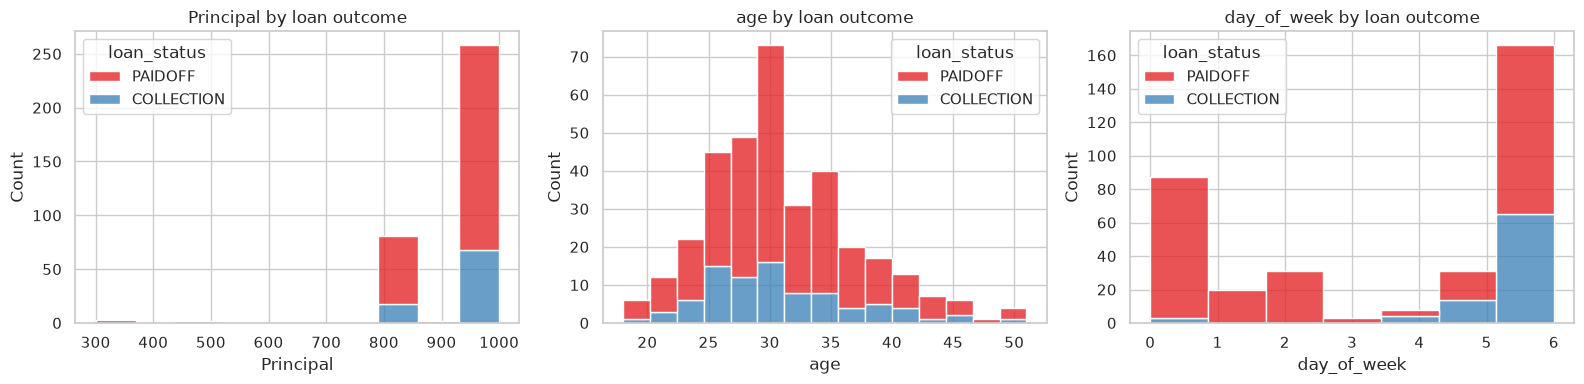

In [5]:
train_df["day_of_week"] = train_df["effective_date"].dt.day_of_week

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, bins in zip(axes, ["Principal", "age", "day_of_week"], [10, 15, 7]):
    sns.histplot(data=train_df, x=col, hue=TARGET, multiple="stack", bins=bins, ax=ax)
    ax.set_title(f"{col} by loan outcome")
plt.tight_layout()
plt.show()

In [6]:
def collection_rate(df: pd.DataFrame, by: str) -> pd.Series:
    # Share of loans that ended in collection for each level of `by`.
    return (df[TARGET].eq("COLLECTION").groupby(df[by]).mean()
            .rename("collection_rate").sort_values(ascending=False))


train_df["weekend"] = (train_df["day_of_week"] > 3).astype(int)
for col in ["Gender", "education", "weekend", "terms"]:
    display(collection_rate(train_df, col).to_frame())

,collection_rate
Gender,
male,0.269
female,0.135


,collection_rate
education,
Master or Above,0.500
High School or Below,0.258
Bechalor,0.250
college,0.235


,collection_rate
weekend,
1,0.405
0,0.021


,collection_rate
terms,
30,0.283
15,0.230
7,0.000


**Key observations**

- Loans originated **from Friday onwards** go to collection far more often (about 40% vs 2%).
- **Female borrowers** default less often than male borrowers.
- Weekly (7-day) loans were all repaid in the training data.
- Education shows little signal; the very small `Master or Above` group is used as the reference level.

## 4. Feature Engineering

One function builds the features for both the training and the test set.

In [7]:
def build_features(df: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray]:
    # Turn a raw loan table into a numeric feature matrix X and target vector y.
    X = pd.DataFrame({
        "Principal": df["Principal"],
        "terms": df["terms"],
        "age": df["age"],
        "female": df["Gender"].eq("female").astype(int),
        "weekend": (df["effective_date"].dt.day_of_week > 3).astype(int),
    })
    for level, name in EDUCATION_LEVELS.items():
        X[f"edu_{name}"] = df["education"].eq(level).astype(int)
    return X, df[TARGET].to_numpy()


X_train, y_train = build_features(train_df)
X_test, y_test = build_features(test_df)
assert list(X_train.columns) == list(X_test.columns)
X_train.head()

,Principal,terms,age,female,weekend,edu_high_school_or_below,edu_college,edu_bachelor
0,1000,30,45,0,0,1,0,0
1,1000,30,33,1,0,0,0,1
2,1000,15,27,0,0,0,1,0
3,1000,30,28,1,1,0,1,0
4,1000,30,29,0,1,0,1,0


## 5. Modelling

### 5.1 Candidate models

- **Benchmarks:** always predicting `PAIDOFF`, and a business rule that flags every loan originated from Friday onwards.
- **Logistic Regression:** primary model; industry standard for credit scoring, with interpretable coefficients and probability scores.
- **Decision Tree:** explainable lending rules.
- **Support Vector Machine:** non-linear challenger.

### 5.2 Hyper-parameter tuning

Stratified 5-fold cross-validation on the training set, maximising macro F1 (both classes weighted equally). Scaling is fitted inside each fold.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    "Logistic Regression": (LogisticRegression(solver="liblinear", max_iter=1000), {
        "clf__C": np.logspace(-3, 2, 30),
        "clf__class_weight": [None, "balanced"],
    }),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        "clf__criterion": ["gini", "entropy"],
        "clf__max_depth": range(2, 13),
        "clf__class_weight": [None, "balanced"],
    }),
    "SVM": (SVC(random_state=RANDOM_STATE), {
        "clf__kernel": ["linear", "rbf", "poly", "sigmoid"],
        "clf__C": [0.01, 0.1, 1, 10, 100],
        "clf__class_weight": [None, "balanced"],
    }),
}

searches = {}
for name, (estimator, grid) in search_spaces.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", estimator)])
    searches[name] = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)

cv_summary = pd.DataFrame({
    name: {"best CV F1 (macro)": s.best_score_,
           "best params": {k.removeprefix("clf__"): v for k, v in s.best_params_.items()}}
    for name, s in searches.items()
}).T
cv_summary

,best CV F1 (macro),best params
Logistic Regression,0.645,"{'C': 0.5736152510448681, 'class_weight': 'bal..."
Decision Tree,0.648,"{'class_weight': 'balanced', 'criterion': 'gin..."
SVM,0.65,"{'C': 0.1, 'class_weight': 'balanced', 'kernel..."


Helper functions to inspect the cross-validation results of each model:

In [9]:
def cv_results(name: str) -> pd.DataFrame:
    # Tidy cross-validation results of one grid search (one row per parameter combination).
    res = pd.DataFrame(searches[name].cv_results_)
    res.columns = [c.replace("param_clf__", "") for c in res.columns]
    if "class_weight" in res:
        # None is stored as a missing value; label it explicitly so it shows up in plots.
        res["class_weight"] = res["class_weight"].map(lambda v: "balanced" if v == "balanced" else "None")
    return res


def best_param(name: str, param: str):
    return searches[name].best_params_[f"clf__{param}"]

### 5.3 Logistic Regression

Cross-validated score by regularisation strength, and coefficients of the selected model:

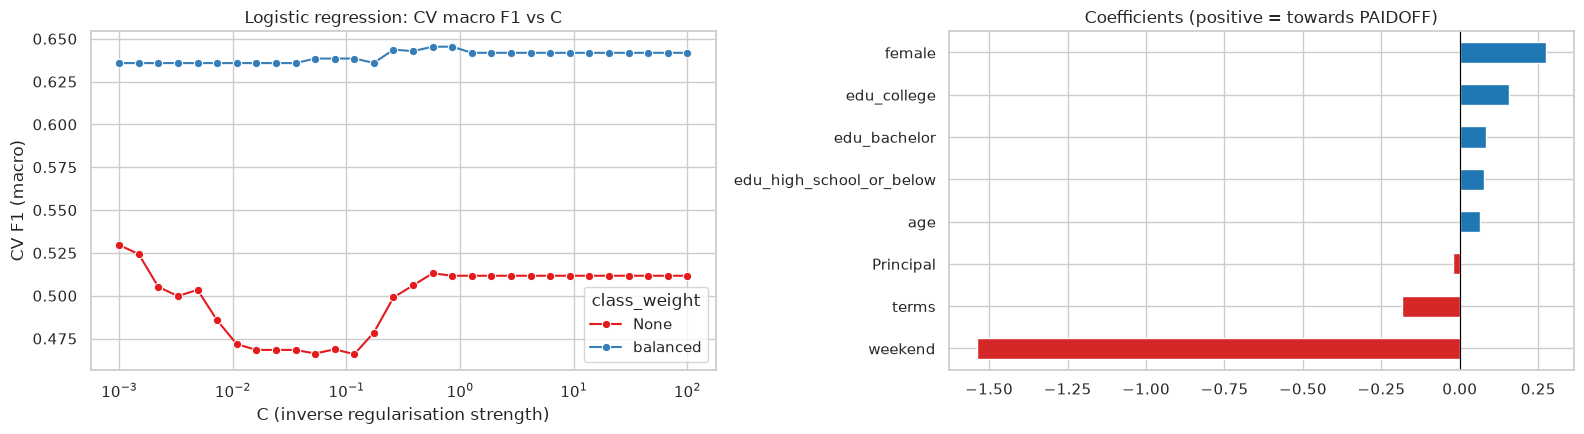

In [10]:
lr = cv_results("Logistic Regression").astype({"C": float})

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.lineplot(data=lr, x="C", y="mean_test_score", hue="class_weight", marker="o", ax=axes[0])
axes[0].set(xscale="log", xlabel="C (inverse regularisation strength)", ylabel="CV F1 (macro)",
            title="Logistic regression: CV macro F1 vs C")

lr_model = searches["Logistic Regression"].best_estimator_.named_steps["clf"]
coefs = pd.Series(lr_model.coef_[0], index=X_train.columns).sort_values()
coefs.plot.barh(ax=axes[1], color=np.where(coefs > 0, "tab:blue", "tab:red"))
axes[1].axvline(0, c="black", lw=0.8)
axes[1].set_title(f"Coefficients (positive = towards {lr_model.classes_[1]})")
plt.tight_layout()
plt.show()

Class weighting raises macro F1 from about 0.5 to 0.64 across almost the whole range of `C`. Weekend origination is by far the strongest driver of collection, while female borrowers and college education lean towards repayment.

### 5.4 Decision Tree

Cross-validated score by tree depth and split criterion:

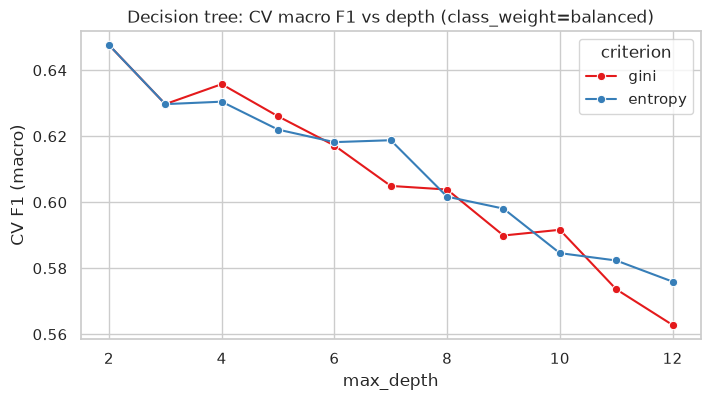

In [11]:
dt = cv_results("Decision Tree")
dt = dt[dt["class_weight"] == str(best_param("Decision Tree", "class_weight"))].astype({"max_depth": int})

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=dt, x="max_depth", y="mean_test_score", hue="criterion", marker="o", ax=ax)
ax.set(xlabel="max_depth", ylabel="CV F1 (macro)",
       title=f"Decision tree: CV macro F1 vs depth (class_weight={best_param('Decision Tree', 'class_weight')})")
plt.show()

The selected tree has only two levels; its first split is the weekend rule:

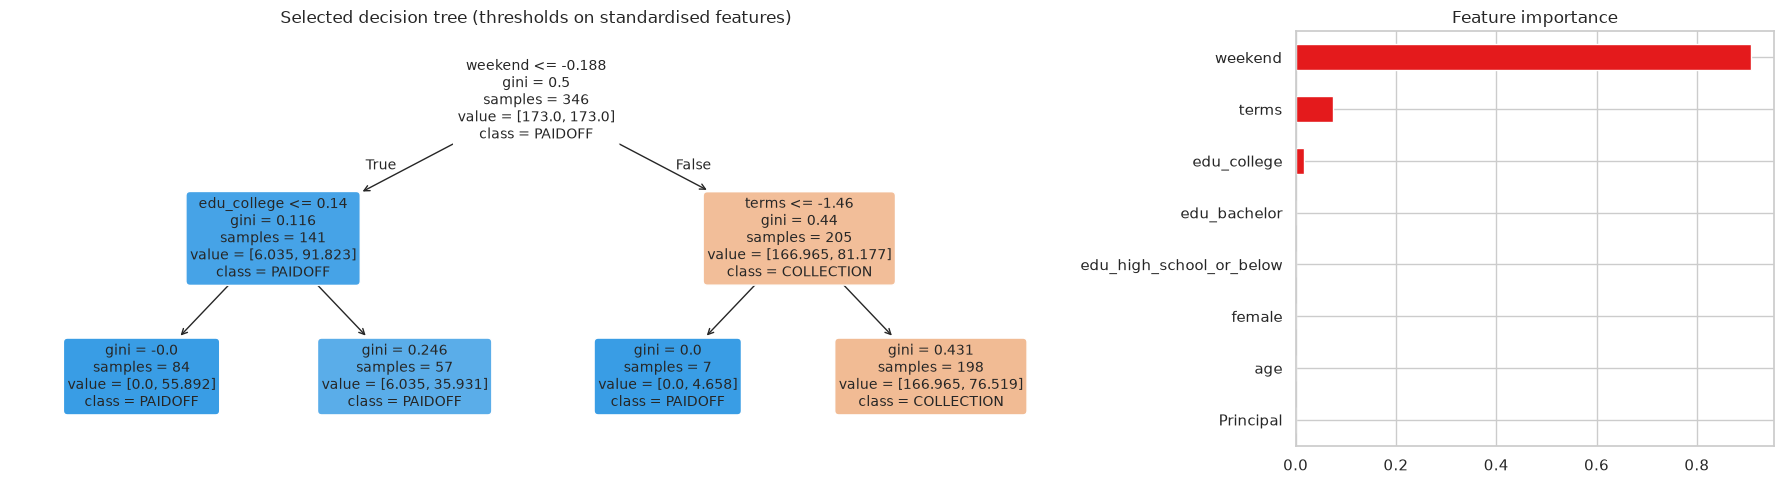

In [12]:
tree_model = searches["Decision Tree"].best_estimator_.named_steps["clf"]

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [2.2, 1]})
plot_tree(tree_model, feature_names=X_train.columns, class_names=tree_model.classes_,
          filled=True, rounded=True, fontsize=10, ax=axes[0])
axes[0].set_title("Selected decision tree (thresholds on standardised features)")
(pd.Series(tree_model.feature_importances_, index=X_train.columns)
   .sort_values().plot.barh(ax=axes[1], title="Feature importance"))
plt.tight_layout()
plt.show()

### 5.5 Support Vector Machine

Cross-validated score by kernel and `C`:

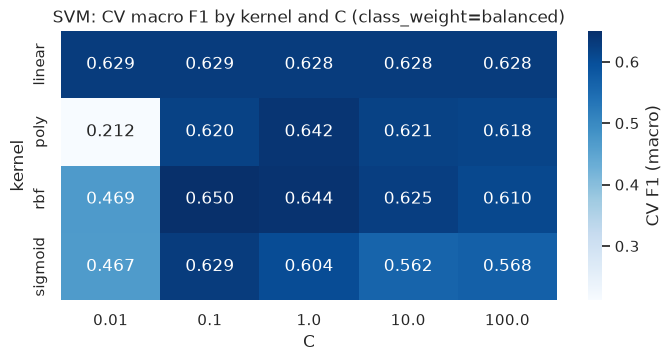

In [13]:
svm = cv_results("SVM")
svm = svm[svm["class_weight"] == str(best_param("SVM", "class_weight"))]
heat = svm.pivot_table(index="kernel", columns="C", values="mean_test_score")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "CV F1 (macro)"}, ax=ax)
ax.set_title(f"SVM: CV macro F1 by kernel and C (class_weight={best_param('SVM', 'class_weight')})")
plt.show()

## 6. Evaluation on the Hold-out Test Set

Each tuned model is refitted on the full training set and scored once on the test set, next to the two benchmarks.

In [14]:
class WeekendRule:
    # Business-rule benchmark: flag every loan originated from Friday onwards.
    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return np.where(X["weekend"] == 1, NEGATIVE_LABEL, POSITIVE_LABEL)


models = {name: s.best_estimator_ for name, s in searches.items()}
models["Weekend rule"] = WeekendRule().fit(X_train, y_train)
models["Baseline (always PAIDOFF)"] = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        "Recall (COLLECTION)": recall_score(y_test, y_pred, pos_label=NEGATIVE_LABEL),
        "Jaccard (PAIDOFF)": jaccard_score(y_test, y_pred, pos_label=POSITIVE_LABEL),
        # Log loss needs class probabilities; SVC and the rule do not provide them.
        "Log loss": (log_loss(y_test, model.predict_proba(X_test), labels=model.classes_)
                     if hasattr(model, "predict_proba") else np.nan),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("Balanced accuracy", ascending=False)
results.style.format("{:.3f}", na_rep="n/a").highlight_max(
    subset=["Balanced accuracy", "F1 (macro)", "Recall (COLLECTION)"], color="#c6efce"
).highlight_min(subset=["Log loss"], color="#c6efce")

,Balanced accuracy,F1 (macro),Recall (COLLECTION),Jaccard (PAIDOFF),Log loss
Model,,,,,
Decision Tree,0.764,0.672,0.929,0.585,1.133
SVM,0.741,0.666,0.857,0.595,n/a
Weekend rule,0.702,0.587,0.929,0.463,n/a
Logistic Regression,0.655,0.578,0.786,0.488,0.561
Baseline (always PAIDOFF),0.500,0.426,0.000,0.741,9.345


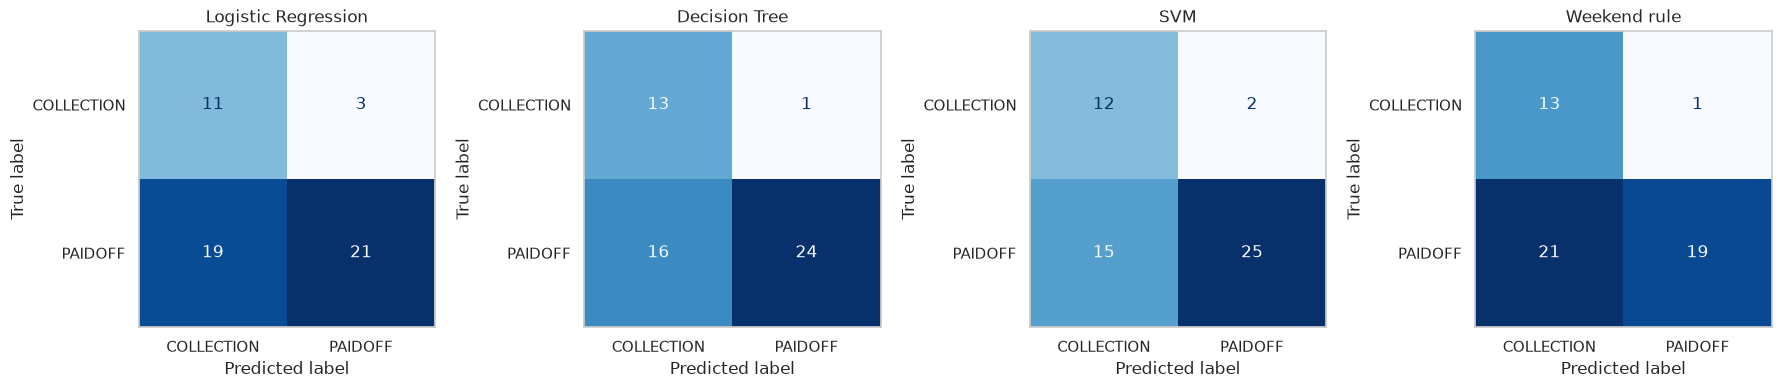

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, model) in zip(axes, list(models.items())[:4]):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

## 7. Conclusions

| Model | Balanced accuracy | Macro F1 | Defaults caught | Good borrowers flagged |
|---|---|---|---|---|
| **Decision Tree** (depth 2, balanced) | **0.76** | **0.67** | **13 / 14** | 16 / 40 |
| SVM (RBF, balanced) | 0.74 | 0.67 | 12 / 14 | 15 / 40 |
| Weekend rule | 0.70 | 0.59 | 13 / 14 | 21 / 40 |
| Logistic Regression (balanced) | 0.66 | 0.58 | 11 / 14 | 19 / 40 |
| Baseline (always PAIDOFF) | 0.50 | 0.43 | 0 / 14 | 0 / 40 |

- **One feature drives the problem.** Loans originated from Friday onwards end in collection 40% of the time, against 2% earlier in the week. This rule alone catches 13 of the 14 defaults in the test set.
- **Accuracy is misleading here.** The "always PAIDOFF" baseline looks competitive on accuracy; only metrics focused on defaults separate useful models from it.
- **Class weighting matters more than the algorithm.** All three tuned models select `class_weight="balanced"`.

### Selected model

The **depth-2 decision tree** is selected: best balanced accuracy and recall, as many defaults caught as the business rule with fewer good borrowers flagged (16 instead of 21), and every decision explainable as two lending rules.

- **Logistic regression** is preferable if the lender needs a risk *score*: it has the best probability estimates (lowest log loss).
- **SVM** performs close to the tree but its decisions are hard to justify to a credit committee or a regulator.
- Catching 13 of 14 defaults costs 16 of 40 good customers; in production, the threshold would be set from the relative cost of a default versus a lost customer.

**Limitations and next steps**

- With 54 test loans (14 defaults), test metrics carry wide uncertainty.
- Cost-sensitive threshold tuning on predicted probabilities.
- Gradient-boosted trees once more data is available.
- Fairness review: gender is predictive here, but its use in credit decisions is restricted in many jurisdictions.